# 01 - Dataset inventory and exploratory analysis
Every number below is computed from the raw files (`src/eda.py`). Raw files are only read.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, json
pd.set_option("display.max_colwidth", 160); pd.set_option("display.width", 200)
%matplotlib inline
from src import eda, data_loader as dl
from src.config import EDA_DIR
print(dl.available_sources())

{'datatourisme': True, 'datatourisme_csv_gz': True, 'huggingface': True, 'events_csv': True, 'mendeley': True}


## A. DATAtourisme (data.gouv.fr) - French tourism events

In [2]:
raw = dl.load_datatourisme()
print(raw.shape)
eda.structural_summary(raw)

(73747, 17)


,dtype,non_null,missing_pct,n_unique,example
id,str,73747,0.00,73747,https://data.datatourisme.fr/10/003a993e-a9e6-30ca-b1b0-be9abb32c33a
label,str,72468,1.73,61852,"{'@value': ""'Arrêtez vos salades!'"", '@language': 'fr'}"
type,str,73747,0.00,1622,schema:Event/CulturalEvent/EntertainmentAndEvent/PointOfInterest/ShowEvent/urn:r
theme,str,0,100.00,0,NaN
startdate,str,0,100.00,0,NaN
enddate,str,0,100.00,0,NaN
street,str,0,100.00,0,NaN
postalcode,str,0,100.00,0,NaN
city,str,0,100.00,0,NaN
insee,str,0,100.00,0,NaN


In [3]:
raw.head(5)

,id,label,type,theme,startdate,enddate,street,postalcode,city,insee,latitude,longitude,email,web,tel,lastupdate,comment
0,https://data.datatourisme.fr/10/003a993e-a9e6-30ca-b1b0-be9abb32c33a,"{'@value': ""'Arrêtez vos salades!'"", '@language': 'fr'}",schema:Event/CulturalEvent/EntertainmentAndEvent/PointOfInterest/ShowEvent/urn:resource,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{'@value': 'Au profit de l\'association RIRE MEDECIN \n\nLa troupe des Gens du coin présente la pièce d\'Olivier Tourancheau ""Arrêtez vos salades!"" . Coméd..."
1,https://data.datatourisme.fr/10/00575426-b21a-3f0b-92a2-ef90f056c268,"{'@value': ""Visite libre de l'ancienne synagogue de Delme, patrimoine local"", '@language': 'fr'}",schema:Event/EntertainmentAndEvent/PointOfInterest/urn:resource,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{'@value': ""Visite libre de l'ancienne synagogue de Delme et son patrimoine architectural. Un historique complet du bâtiment est à votre disposition à l'acc..."
2,https://data.datatourisme.fr/10/0067aadc-63b1-3f83-a9cc-ea824640cb91,"{'@value': 'Ateliers, stages de loisirs - Même pas peur !', '@language': 'fr'}",schema:Event/schema:Product/ChildrensEvent/CulturalEvent/EntertainmentAndEvent/PointOfInterest/Practice/Product/Traineeship/urn:resource,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{'@value': ""Halloween s'invite à la médiathèque. Sorcières, fantômes, monstres farceurs et créatures extraordinaires sont invités à envahir la médiathèque l..."
3,https://data.datatourisme.fr/10/007f1bff-bd45-3ed8-935c-1cd5bae5c122,"{'@value': ""Suz'alloween"", '@language': 'fr'}",schema:Event/EntertainmentAndEvent/PointOfInterest/urn:resource,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{'@value': ""Venez frissonner à bord de nos vélorails à la Gare du Varinot pour Halloween !\n\nVélorail, chamboule-tout, boite à mystère, histoire...\n\nLa S..."
4,https://data.datatourisme.fr/10/007f44b3-241c-3df4-81b1-d50d49a35d2c,"{'@value': 'Concert - Rod Barthet & Guests', '@language': 'fr'}",schema:Event/schema:MusicEvent/Concert/CulturalEvent/EntertainmentAndEvent/PointOfInterest/ShowEvent/urn:resource,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{'@value': 'Rod BARTHET invite Fred CHAPELLIER, Neal BLACK & Eric SAUVIAT\n\nImaginez une seule scène avec quatre des plus grands ambassadeurs du blues hexa..."


In [4]:
dec = dl.decode_datatourisme(raw)
dec[['title','type_labels','description']].sample(5, random_state=1)

,title,type_labels,description
2460,Les Ombres du Parc des Sources,[],"À la tombée de la nuit, le Parc des Sources s’éveille et…révèle son visage le plus mystérieux… Oserez-vous traverser l’allée centrale ?"
55659,Les bébés lecteurs,"[jeune public, événement culturel]",NaN
41157,Atelier d'écriture : séances du vendredi,[],NaN
22573,"10 ANS, 10 TERRILS - Le terril sportif : le terril 94 – Arena Terril Trail de Noyelles-sous-Lens",[],Comment fêter les 10 ans de l’inscription du Bassin minier sur la Liste du patrimoine mondial de l’UNESCO sans rendre hommage à nos pyramides noires ? Pour ...
1894,Festival Foodtruck -,[],NaN


In [5]:
dt = eda.eda_datatourisme(save=True)
{k: v for k, v in dt.items() if k not in ('columns',)}

{'source': 'DATAtourisme - data.gouv.fr (Licence Ouverte / Etalab 2.0)',
 'rows': 73747,
 'memory_mb': np.float64(36.6),
 'fully_empty_columns': ['theme',
  'startdate',
  'enddate',
  'street',
  'postalcode',
  'city',
  'insee',
  'latitude',
  'longitude',
  'email',
  'web',
  'tel',
  'lastupdate'],
 'duplicate_ids': 0,
 'corrupted_type_rows': 16456,
 'title': {'non_null': 72468,
  'null': 1279,
  'empty': 0,
  'chars_mean': 35.3,
  'chars_min': 1,
  'chars_max': 201,
  'words_mean': 5.8,
  'words_median': 5.0,
  'words_min': 1,
  'words_max': 32,
  'very_short_lt_8_words': 54121,
  'duplicate_texts': 10616,
  'with_html_tags': 0,
  'with_urls': 0,
  'with_markdown_bold': 8,
  'language_share_sample': {'fr': 0.516, 'unknown': 0.465, 'en': 0.019}},
 'description': {'non_null': 39113,
  'null': 34634,
  'empty': 1,
  'chars_mean': 190.9,
  'chars_min': 1,
  'chars_max': 4983,
  'words_mean': 30.5,
  'words_median': 23.0,
  'words_min': 0,
  'words_max': 759,
  'very_short_lt_8_word

**Reading.** 13 of the 17 columns (theme, dates, address, city, coordinates, contacts, lastupdate)
are **100 % empty** in this extract: only `id`, `label` (title), `type` (ontology path) and `comment`
(description) carry information. Descriptions are French, short (median ≈ 26 words) and real
(written by tourist offices). This limits the input to *title + event type*.

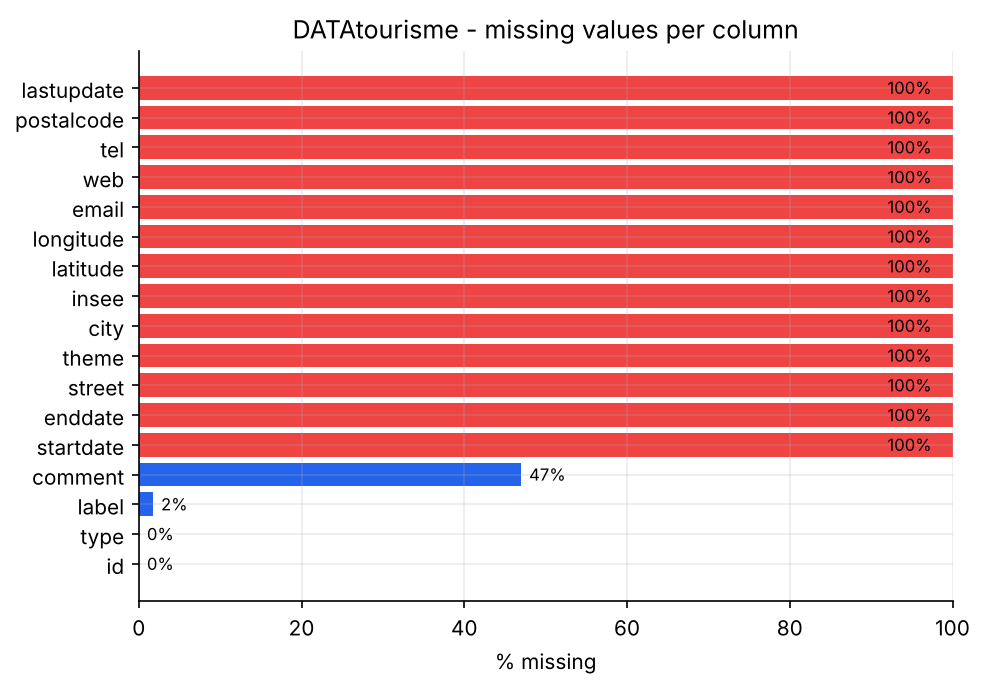

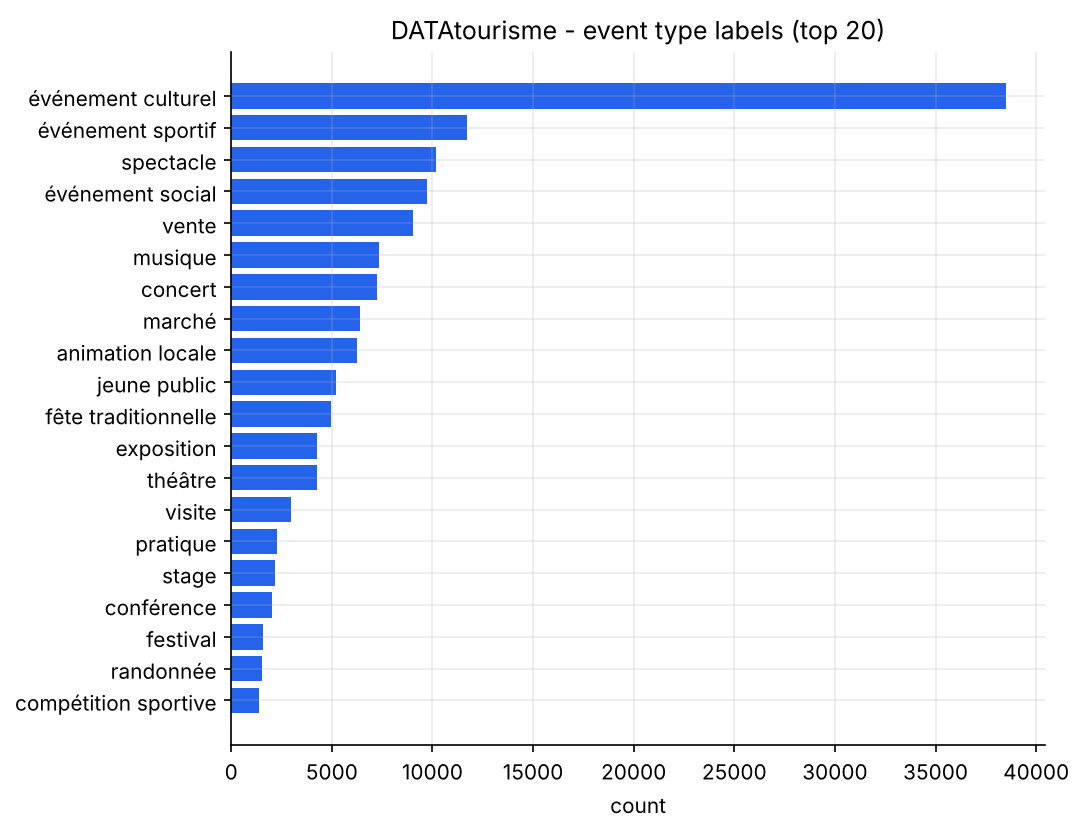

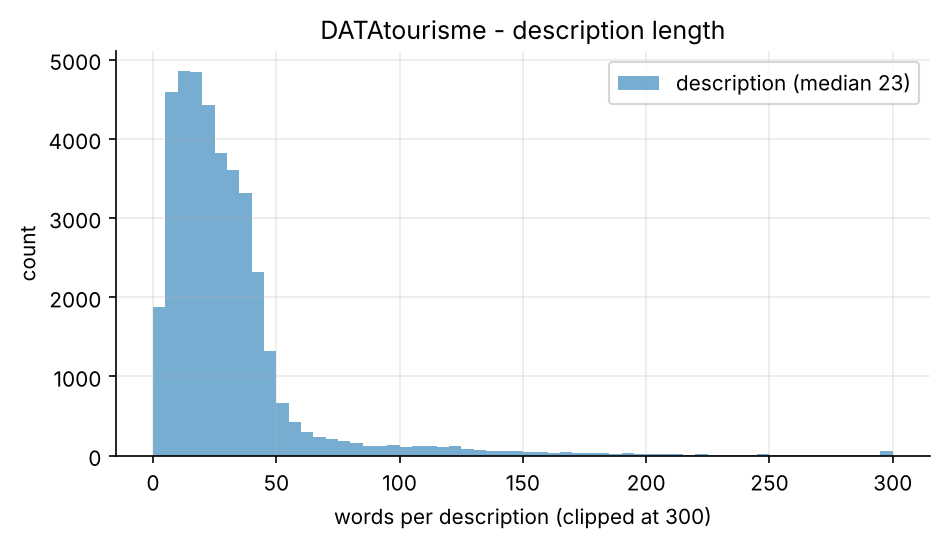

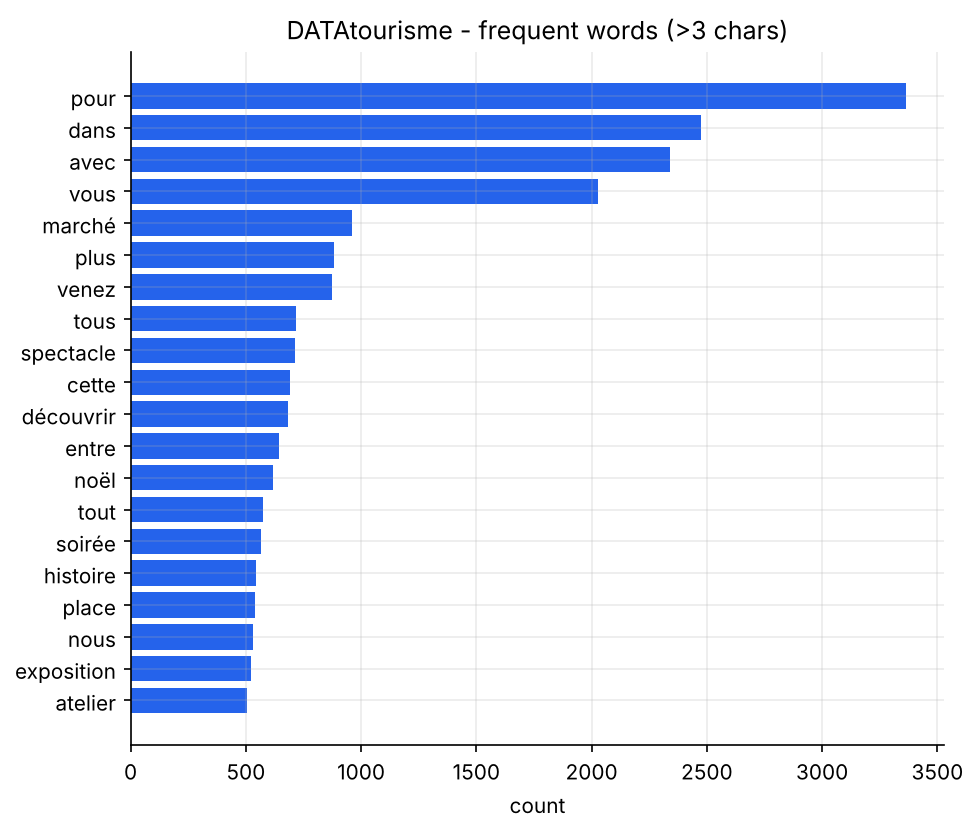

In [6]:
from IPython.display import Image, display
for f in ['datatourisme_missing','datatourisme_types','datatourisme_lengths','datatourisme_words']:
    display(Image(EDA_DIR / f'{f}.png'))

## B. Hugging Face `eliel2003/events`

In [7]:
hf = dl.load_huggingface(); print(hf.shape)
display(eda.structural_summary(hf))
print(hf.event_narrative.iloc[0][:800])

(3000, 19)


,dtype,non_null,missing_pct,n_unique,example
event_id,str,3000,0.0,3000,EVT-00001
event_type,str,3000,0.0,10,Tech Summit
client_industry,str,3000,0.0,8,Retail
city,str,3000,0.0,8,Petah Tikva
month,int64,3000,0.0,12,10
month_name,str,3000,0.0,12,October
year,int64,3000,0.0,4,2023
season,str,3000,0.0,4,Fall
guest_capacity,int64,3000,0.0,14,500
catering_style,str,3000,0.0,6,Plated Fine Dining


**Objective:** The primary objective of this tech summit was to foster innovation and collaboration among retail industry professionals through workshops on emerging technologies that could enhance customer experiences.

**Execution Highlights:**

- **Interactive Workshops:** A series of hands-on workshops introduced attendees to cutting-edge technologies such as augmented reality (AR) in store design and AI-driven analytics for inventory management.
  
- **Networking Events:** Multiple networking opportunities were set up throughout the day including breakouts sessions where participants engaged with vendors and peers over coffee or light refreshments.
   
- **Inclusion of Vendor Presentations:** Keynote speakers from various technology firms shared insights into their products, services,


In [8]:
eda.eda_huggingface(save=True)

{'source': 'Hugging Face eliel2003/events (synthetic event-management data)',
 'rows': 3000,
 'columns': ['event_id',
  'event_type',
  'client_industry',
  'city',
  'month',
  'month_name',
  'year',
  'season',
  'guest_capacity',
  'catering_style',
  'av_complexity',
  'total_budget_usd',
  'actual_spend_usd',
  'margin_pct',
  'vendor_count',
  'vendor_ids_used',
  'vendor_cost_breakdown',
  'success_rating',
  'event_narrative'],
 'memory_mb': np.float64(3.8),
 'duplicate_rows': 0,
 'duplicate_ids': 0,
 'categorical_cardinality': {'event_type': 10,
  'client_industry': 8,
  'city': 8,
  'season': 4,
  'catering_style': 6},
 'event_narrative': {'non_null': 3000,
  'null': 0,
  'empty': 0,
  'chars_mean': 799.3,
  'chars_min': 580,
  'chars_max': 946,
  'words_mean': 103.7,
  'words_median': 104.0,
  'words_min': 75,
  'words_max': 119,
  'very_short_lt_8_words': 0,
  'duplicate_texts': 0,
  'with_html_tags': 0,
  'with_urls': 0,
  'with_markdown_bold': 2463,
  'language_share_sam

**Reading.** Clean and complete, with rich structured fields, but **synthetic** (LLM-generated)
and only 3 000 rows. The narratives are *post-event reports* in markdown (Objective / Execution
highlights / Outcome), not promotional descriptions, and long (~104 words) for an LSTM decoder.

## C. Events.csv (Irish events)

In [9]:
ev = dl.load_events_csv(); print(ev.shape)
display(eda.structural_summary(ev))
eda.eda_events_csv(save=True)

(3977, 20)


,dtype,non_null,missing_pct,n_unique,example
Name,str,3977,0.00,874,The Moving Crib
Event Type,str,3977,0.00,3,Event
Description,str,3977,0.00,897,"Experience the magic of Christmas at The Moving Crib, one of Dublin's best-loved"
Image,str,3977,0.00,917,https://assets-eu-01.kc-usercontent.com:443/aa24ba70-9a12-01ae-259b-7ef588a0b2ef
Contact URL,str,3977,0.00,839,https://www.stmartin.ie/crib/
Booking URL,str,3558,10.54,828,https://themovingcrib.ie/
Contact Phone Number,float64,2192,44.88,140,35318745465.0
Booking Phone Number,float64,1406,64.65,104,35318745465.0
Venue Name,str,3977,0.00,252,"The Moving Crib, St Martin Apostolate"
Address,str,3977,0.00,245,"42 Parnell Square W, Rotunda, Dublin, Dublin"


{'source': 'Events.csv - Irish events listing (URLs point to Irish venues, County column = Irish counties)',
 'rows': 3977,
 'columns': ['Name',
  'Event Type',
  'Description',
  'Image',
  'Contact URL',
  'Booking URL',
  'Contact Phone Number',
  'Booking Phone Number',
  'Venue Name',
  'Address',
  'County',
  'Latitude',
  'Longitude',
  'Is Free To Visit',
  'Price',
  'Start Date',
  'End Date',
  'Start Time',
  'End Time',
  'Recurring Dates'],
 'memory_mb': np.float64(5.1),
 'duplicate_rows': 1,
 'unique_names': 874,
 'unique_descriptions': 897,
 'event_type_values': {'Event': 3707, 'Festival': 264, 'Market': 6},
 'county_top': {'Dublin': 2970,
  'Cork': 179,
  'Kerry': 174,
  'Waterford': 122,
  'Louth': 107,
  'Galway': 76,
  'Wexford': 60,
  'Kilkenny': 49},
 'description': {'non_null': 3977,
  'null': 0,
  'empty': 0,
  'chars_mean': 654.1,
  'chars_min': 159,
  'chars_max': 840,
  'words_mean': 104.7,
  'words_median': 111.0,
  'words_min': 26,
  'words_max': 145,
  'v

**Reading.** English, real descriptions, but each event is repeated once per date: only
≈ 900 unique descriptions remain, which is too few to train a seq2seq model from scratch.
It also contains contact phone numbers and URLs.

## D. Mendeley (DOI 10.17632/g2sdzmssgh.2)

In [10]:
men = eda.eda_mendeley(save=True)
men

{'source': 'Mendeley Data DOI 10.17632/g2sdzmssgh.2 (life-event narratives generated by an AI model)',
 'files': {'human_tagged_original/tagged_birth_messages.csv': {'rows': 720,
   'columns': ['TEXT', 'CLASSIFICATION']},
  'human_tagged_original/tagged_death_messages.csv': {'rows': 705,
   'columns': ['TEXT', 'CLASSIFICATION']},
  'human_tagged_original/tagged_fired_messages.csv': {'rows': 735,
   'columns': ['TEXT', 'CLASSIFICATION']},
  'human_tagged_original/tagged_hired_messages.csv': {'rows': 720,
   'columns': ['TEXT', 'CLASSIFICATION']},
  'human_tagged_validation/aggregated_birth_narrative_validation_results.csv': {'rows': 53,
   'columns': ['STUDY_ID',
    'TITLE',
    'REVIEWERS',
    'YES',
    'NO',
    'ABSTRACT',
    'INCLUDE']},
  'human_tagged_validation/aggregated_death_narrative_validation_results.csv': {'rows': 53,
   'columns': ['STUDY_ID',
    'TITLE',
    'REVIEWERS',
    'YES',
    'NO',
    'ABSTRACT',
    'INCLUDE']},
  'human_tagged_validation/aggregated_fire

In [11]:
files = dl.load_mendeley(); k = next(iter(files)); print(k)
print(files[k].iloc[0, 0][:1200])

**Reading.** Life-event narratives (hiring, firing, birth, death) written by an AI model for
simulated personas, plus human/AI *classification* labels ("does the narrative match the prompt?").
They are not organised events, the labels are classification targets (not generation targets) and the
prompts contain sensitive persona attributes (gender, minority group, income). **Excluded.**

## Size comparison and decision

In [12]:
res = eda.run_all(save=False)
sizes = eda.dataset_size_comparison(res, save=True)
sizes

DATAtourisme (with description)    39113
Hugging Face                        3000
Mendeley (human-tagged orig.)       2880
Events.csv (unique desc.)            897
dtype: int64

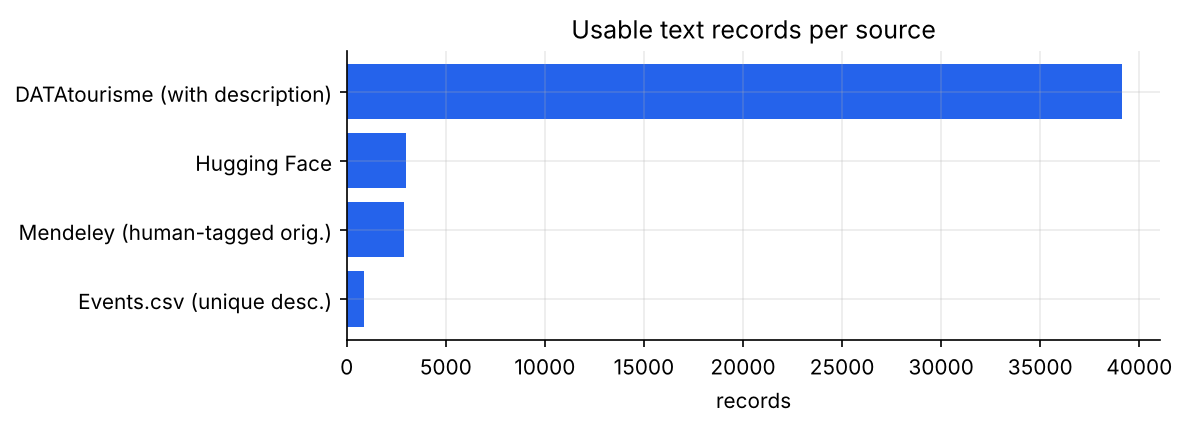

In [13]:
display(Image(EDA_DIR / 'dataset_sizes.png'))

| Canonical field | DATAtourisme | Hugging Face | Events.csv | Mendeley |
|---|---|---|---|---|
| Event name | `label` | - (only `event_id`) | `Name` | - |
| Event type | `type` (ontology path) | `event_type` | `Event Type` (3 values) | life event kind |
| Location | empty | `city` (Israel) | `Venue Name`, `County` | persona location |
| Date | empty | `month`, `year`, `season` | `Start Date` | - |
| Audience / objective / tone | - | - | - | - |
| Description | `comment` (FR, real) | `event_narrative` (EN, synthetic) | `Description` (EN) | AI-generated narrative |
| Language | French | English | English | English |

**Decision.** Primary dataset: **DATAtourisme** (largest real corpus, short targets suited to an LSTM,
a single language). Hugging Face, Events.csv and Mendeley are **not merged**: different languages,
writing styles (report vs. promotion vs. personal post) and input schemas would make P(Y|X) incoherent.
`evenements.csv.gz` is another extract of the same DATAtourisme feed (same schema, most ids shared) and is
not needed.